# WattWitness — Phase 1 walkthrough

This notebook explores the one-year simulated node, shows why the ideal data are too perfect to test physics checks on, and summarises the detection results. **Building load, context, dispatch and electrical channels are synthetic or derived, and meter error is modelled; nothing here is a field measurement.** Run the pipeline first (`python scripts/run_phase1_pipeline.py`).

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'scripts'))
from detect_evaluate import residuals, FEATURES
ideal = pd.read_csv(ROOT / 'data/simulated_microgrid_1y.csv', parse_dates=['Timestamp'])
measured = pd.read_csv(ROOT / 'data/measured_telemetry_1y.csv', parse_dates=['Timestamp'])
print('Rows:', len(measured), '|', measured.Timestamp.min(), 'to', measured.Timestamp.max())
print('Rows with at least one unknown value:', int(measured[FEATURES].isna().any(axis=1).sum()))
pd.DataFrame({'ideal |residual| max': residuals(ideal).abs().max(),
              'measured |residual| 99.9th pct': residuals(measured).abs().quantile(0.999)}).round(4)

Rows: 8784 | 2023-06-01 00:00:00 to 2024-05-31 23:00:00
Rows with at least one unknown value: 39


,ideal |residual| max,measured |residual| 99.9th pct
power_balance_kw,0.0000,5.6000
pv_dc_kw,0.0086,6.1047
pv_ac_kw,0.0083,6.0226
grid_kw,0.0000,3.1362
battery_current_a,0.0000,5.4131
pv_source_vs_inverter_kw,0.0000,5.8000


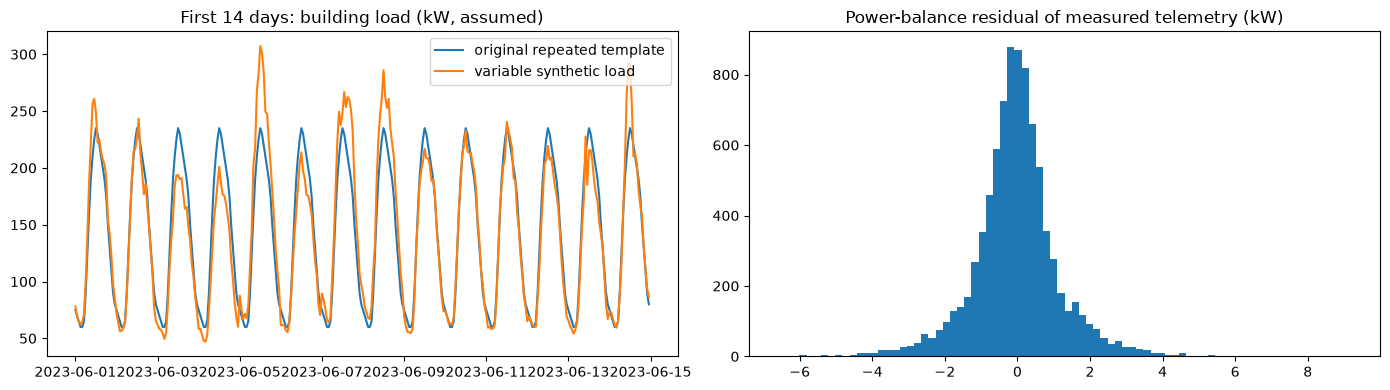

In [2]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
w = ideal.iloc[:24 * 14]
axs[0].plot(w.Timestamp, w['Source Template Load (reference only)'], label='original repeated template')
axs[0].plot(w.Timestamp, w['Building Load'], label='variable synthetic load')
axs[0].set_title('First 14 days: building load (kW, assumed)'); axs[0].legend()
axs[1].hist(residuals(measured)['power_balance_kw'].dropna(), bins=80)
axs[1].set_title('Power-balance residual of measured telemetry (kW)')
plt.tight_layout()

In [3]:
summary = json.loads((ROOT / 'outputs/evaluation_summary.json').read_text())
print('Learned physics limits:', {k: round(v, 2) for k, v in summary['physics_thresholds'].items()})
pd.read_csv(ROOT / 'outputs/evaluation_metrics.csv').round(3)

Learned physics limits: {'power_balance_kw': 6.8, 'pv_dc_kw': 7.6, 'pv_ac_kw': 7.19, 'grid_kw': 3.89, 'battery_current_a': 6.43, 'pv_source_vs_inverter_kw': 6.92}


,detector,precision,recall,f1,average_precision,tp,fp,fn,tn
0,Rules only,1.000,0.182,0.309,0.273,29,0,130,1279
1,Physical checks only,0.984,0.792,0.878,0.803,126,2,33,1277
2,Rules + physics (selected),0.986,0.881,0.930,0.881,140,2,19,1277
3,Isolation Forest,0.267,0.145,0.188,0.182,23,63,136,1216
4,Full hybrid (rules + physics + Isolation Forest),0.684,0.887,0.773,0.619,141,65,18,1214


In [4]:
pd.read_csv(ROOT / 'outputs/fault_type_recall.csv').round(2)

,fault_type,events,affected_rows,rules_recall,physics_recall,hybrid_recall,events_detected
0,delayed_signal,3,36,0.00,1.00,1.00,3
1,frozen,3,21,0.71,0.95,1.00,3
2,gradual_drift,3,69,0.01,0.77,0.78,3
3,missing,3,12,1.00,0.00,1.00,3
4,plausible_bias,3,18,0.00,0.78,0.78,3
5,spike,3,3,0.33,1.00,1.00,3


In [5]:
events = pd.read_csv(ROOT / 'outputs/event_level_results.csv')
print(f"Events flagged: {int(events.detected.sum())}/{len(events)}, fully: {int(events.fully_detected.sum())}")
events[['event_id', 'fault_type', 'severity', 'altered_rows', 'flagged_rows', 'hours_to_first_flag']]

Events flagged: 18/18, fully: 14


,event_id,fault_type,severity,altered_rows,flagged_rows,hours_to_first_flag
0,F01,spike,single-sample upward spike of +200 kW,1,1,0
1,F02,frozen,sensor holds one value for 8 hours,7,7,0
2,F03,gradual_drift,linear positive drift reaching 35% of the read...,23,18,4
3,F04,missing,four missing hourly values,4,4,0
4,F05,delayed_signal,PV signal replayed with a 3-hour delay,12,12,0
5,F06,plausible_bias,grid-current reading increased by 12%,6,6,0
6,F07,spike,single-sample upward spike of +80 kW,1,1,0
7,F08,frozen,sensor holds one value for 8 hours,7,7,0
8,F09,gradual_drift,linear positive drift reaching 35% of the read...,23,18,4
9,F10,missing,four missing hourly values,4,4,0


In [6]:
pd.read_csv(ROOT / 'outputs/noise_robustness.csv').round(3)

,noise_scale,power_meter_error_pct,thresholds,precision,recall,f1,clean_window_alert_rate_pct
0,0.0,0.00,fixed 2 kW / 5 A limits (v0.1),0.963,0.981,0.972,0.626
1,0.0,0.00,limits calibrated on training data,0.964,1.000,0.981,0.626
2,0.5,0.25,fixed 2 kW / 5 A limits (v0.1),0.816,0.975,0.888,2.712
3,0.5,0.25,limits calibrated on training data,1.000,0.956,0.977,0.070
4,1.0,0.50,fixed 2 kW / 5 A limits (v0.1),0.363,0.981,0.530,21.697
5,1.0,0.50,limits calibrated on training data,0.986,0.881,0.930,0.209
6,2.0,1.00,fixed 2 kW / 5 A limits (v0.1),0.206,0.981,0.340,47.705
7,2.0,1.00,limits calibrated on training data,0.982,0.698,0.816,0.209
8,4.0,2.00,fixed 2 kW / 5 A limits (v0.1),0.142,0.987,0.248,74.200
9,4.0,2.00,limits calibrated on training data,0.973,0.459,0.624,0.209


In [7]:
queue = pd.read_csv(ROOT / 'outputs/review_queue.csv')
print('Alerts waiting for review:', len(queue))
pd.set_option('display.max_colwidth', 140)
queue[['Timestamp', 'interpretation', 'evidence_score', 'explanation']].head(8)

Alerts waiting for review: 144


,Timestamp,interpretation,evidence_score,explanation
0,2024-04-04 20:00:00,Likely telemetry / data inconsistency,0.95,Grid Power jumped by +179 and reversed on the next sample; Power-flow balance (sources vs uses) off by 199.6 kW (limit 6.8 kW); Grid pow...
1,2024-04-06 10:00:00,Likely telemetry / data inconsistency,0.82,PV meter vs PV inverter output off by 23.9 kW (limit 6.9 kW).
2,2024-04-06 11:00:00,Likely telemetry / data inconsistency,0.89,PV meter vs PV inverter output off by 33.3 kW (limit 6.9 kW).
3,2024-04-06 12:00:00,Likely telemetry / data inconsistency,0.95,PV Power repeated exactly 288.4 for 4+ hours; PV meter vs PV inverter output off by 47.8 kW (limit 6.9 kW).
4,2024-04-06 13:00:00,Likely telemetry / data inconsistency,0.91,PV Power repeated exactly 288.4 for 4+ hours; PV meter vs PV inverter output off by 35.8 kW (limit 6.9 kW).
5,2024-04-06 14:00:00,Likely telemetry / data inconsistency,0.95,PV Power repeated exactly 288.4 for 4+ hours; PV meter vs PV inverter output off by 70.1 kW (limit 6.9 kW).
6,2024-04-06 15:00:00,Likely telemetry / data inconsistency,0.95,PV Power repeated exactly 288.4 for 4+ hours; PV meter vs PV inverter output off by 79.1 kW (limit 6.9 kW).
7,2024-04-06 16:00:00,Likely telemetry / data inconsistency,0.95,PV Power repeated exactly 288.4 for 4+ hours; PV meter vs PV inverter output off by 120.5 kW (limit 6.9 kW).


## Reproduce

```bash
pip install -r requirements.txt
python scripts/run_phase1_pipeline.py
python -m unittest discover -s tests -v
```

Scores are results on deliberately injected synthetic faults. The clean-window alert rate is not a verified false-positive rate.